# 02 – Předzpracování (filtrace)

In [1]:
# přenačtení jednotlivých python souborů
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from coins.io import load_rgb, show_images, SAMPLE_DIR
from coins.preprocess import to_v

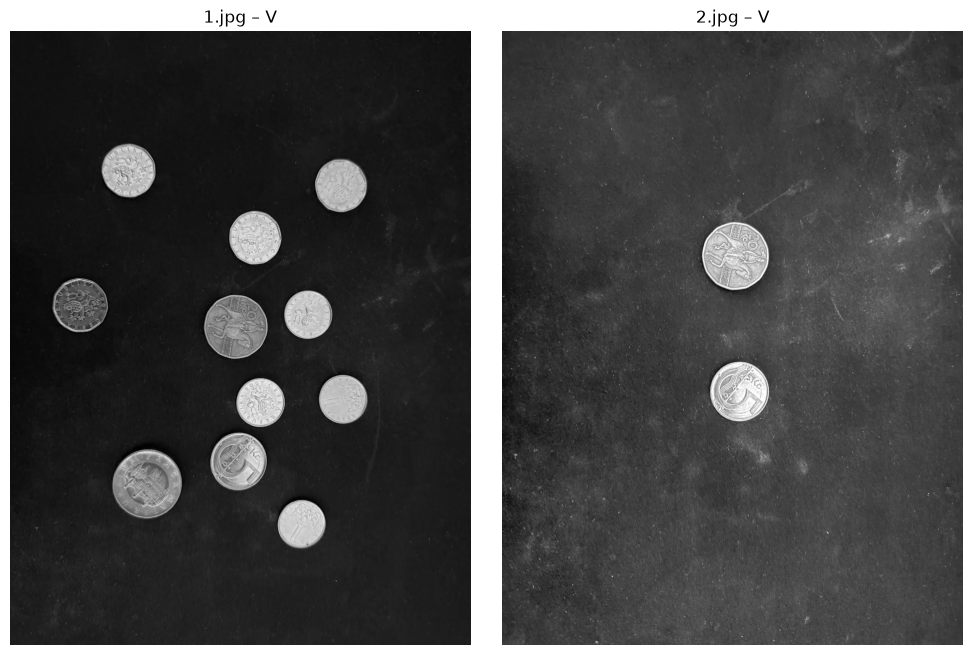

None


In [4]:
v1 = to_v(load_rgb(SAMPLE_DIR / "1.jpg"))
v2 = to_v(load_rgb(SAMPLE_DIR / "2.jpg"))

print(show_images([v1, v2], ["1.jpg – V", "2.jpg – V"]))

## Filtry na reálné fotce

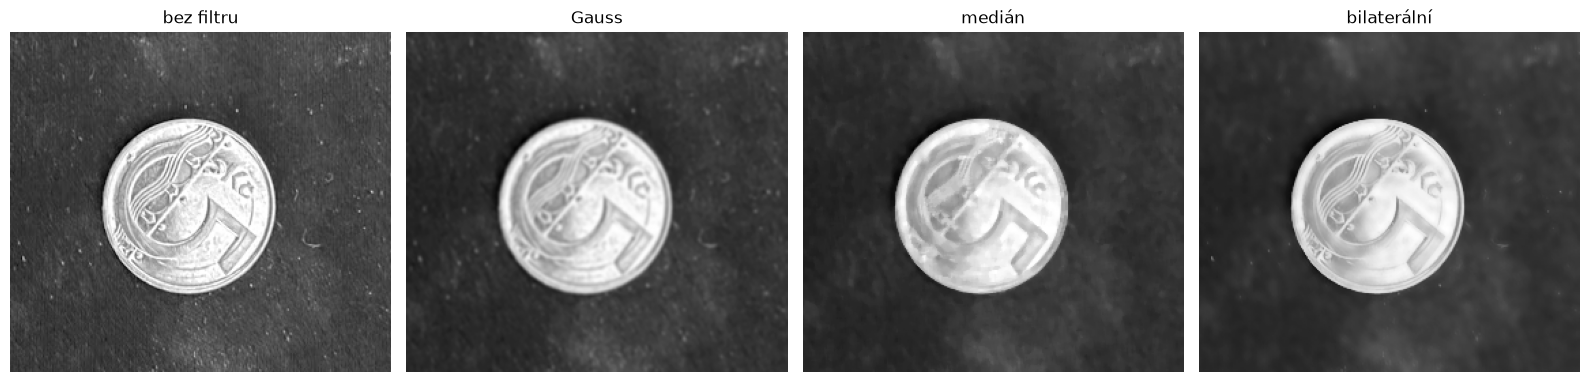

In [9]:
def apply_filters(v, k=5):
    return {
        "bez filtru": v,
        "Gauss": cv2.GaussianBlur(v, (k, k), 0),
        "medián": cv2.medianBlur(v, k), # tohle když tak vybereme protože tam nejsou kolem toho ty bíle tečky
        "bilaterální": cv2.bilateralFilter(v, 9, 50, 5),
    }

f2 = apply_filters(v2)
# chceme pouze 5 korunu abychom to porovnali
crop = (slice(650, 900), slice(380, 660))
show_images([img[crop] for img in f2.values()], list(f2.keys()), cols=4, size=4)

## Vliv na prahování (Otsu)

In [6]:
def otsu_blobs(v, min_area=2000):
    _, mask = cv2.threshold(v, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, _, stats, _ = cv2.connectedComponentsWithStats(mask)
    areas = stats[1:, cv2.CC_STAT_AREA]
    return mask, (areas >= min_area).sum(), (areas < min_area).sum()

for name, v in [("1.jpg", v1), ("2.jpg", v2)]:
    print(name)
    for fname, img in apply_filters(v).items():
        _, big, small = otsu_blobs(img)
        print(f"  {fname:12s} mince={big:2d}  smetí={small:4d}")

1.jpg
  bez filtru   mince=10  smetí=  83
  Gauss        mince=10  smetí=  26
  medián       mince=10  smetí=  42
  bilaterální  mince=10  smetí=  44
2.jpg
  bez filtru   mince= 2  smetí= 428
  Gauss        mince= 2  smetí=  30
  medián       mince= 2  smetí=   7
  bilaterální  mince= 2  smetí=  25


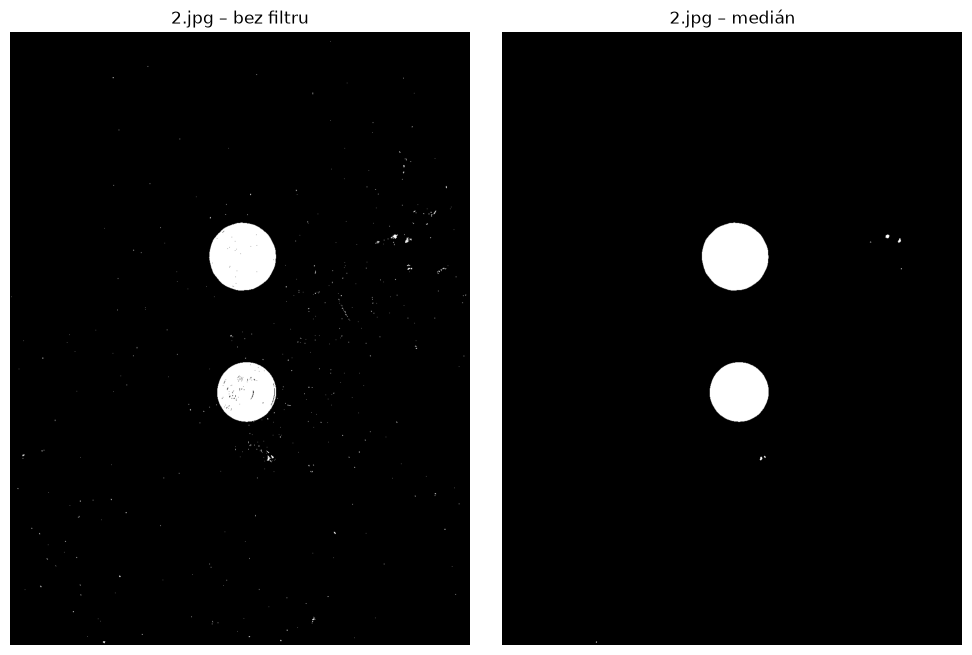

In [8]:
masks = [otsu_blobs(f2[n])[0] for n in ["bez filtru", "medián"]]
show_images(masks, ["2.jpg – bez filtru", "2.jpg – medián"], cols=2)

## PSNR na uměle zašuměném snímku

Gauss šum
  bez filtru    22.9 dB
  Gauss         31.3 dB
  medián        30.7 dB
  bilaterální   33.0 dB
Salt & Pepper
  bez filtru    16.2 dB
  Gauss         25.7 dB
  medián        33.5 dB
  bilaterální   16.3 dB


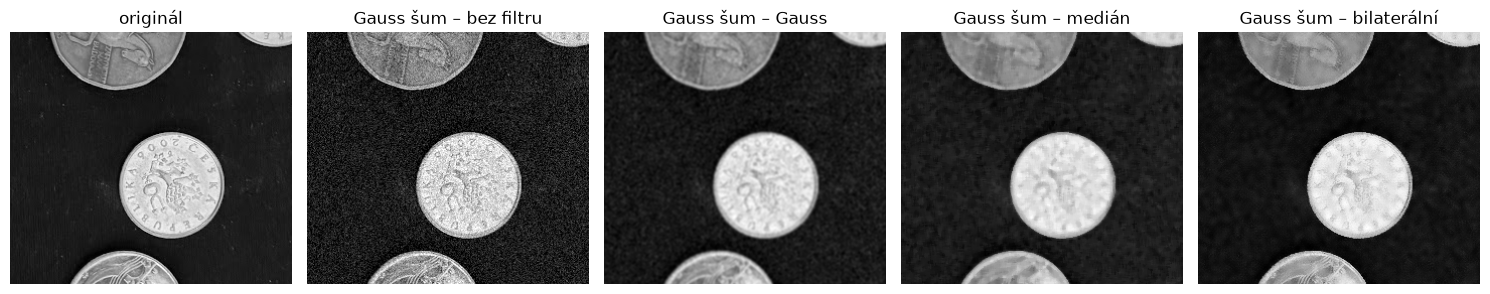

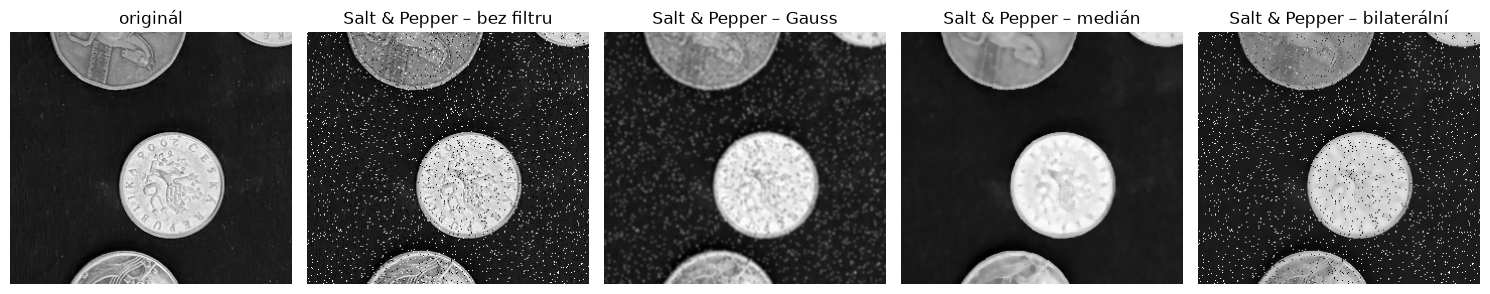

In [11]:
def psnr(orig, test):
    mse = np.mean((orig.astype(np.float32) - test.astype(np.float32)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)

rng = np.random.default_rng(42)
gauss_noise = np.clip(v1 + rng.normal(0, 20, v1.shape), 0, 255).astype(np.uint8)

sp_noise = v1.copy()
r = rng.random(v1.shape)
sp_noise[r < 0.03] = 0
sp_noise[r > 0.97] = 255

for name, noisy in [("Gauss šum", gauss_noise), ("Salt & Pepper", sp_noise)]:
    print(name)
    for fname, img in apply_filters(noisy).items():
        print(f"  {fname:12s} {psnr(v1, img):5.1f} dB")

for name, noisy in [("Gauss šum", gauss_noise), ("Salt & Pepper", sp_noise)]:
    filtered = apply_filters(noisy)
    images = [v1] + list(filtered.values())
    titles = ["originál"] + [f"{name} – {fname}" for fname in filtered]
    show_images([img[crop] for img in images], titles, cols=5, size=3)

# tohle jsme řešili na přednášce kaž